# 04 — Zhang et al. (2025) DeSCN-GIF: graph-intuitionistic-fuzzy sample weights under label noise

**Method (IEEE TFS):** each training sample gets a weight from its k-NN neighbourhood
(membership μ from same-class Gaussian similarity, non-membership ν from neighbour contamination,
hesitation π, class-imbalance compensation), so likely mislabelled points count less. Their data
(depression speech) is private; the weighting is transferred to the 4 diabetes datasets with
LightGBM as the learner (as in the audit's R07), with and without GIF weights.

Label noise: a fraction r ∈ {0, 0.1, 0.2, 0.3, 0.4} of **training** labels is flipped
(symmetric). Test labels are never corrupted.

**Protocols**
* `paper` — GIF weights computed on all rows (noisy labels of the test fold included in the kNN
  graph), ungrouped stratified 5-fold, seed 42.
* `clean` — weights from the training fold only; grouped/stratified 5-fold × seeds {0, 1, 42}.

Primary metric for this paper: G-mean = √(recall × specificity).

In [1]:
import os, sys
from pathlib import Path
for p in [Path.cwd(), Path.cwd() / "notebooks2", Path("/content/notebooks2"), *Path("/kaggle/input").glob("*"), *Path("/kaggle/input").glob("*/notebooks2")]:
    if (p / "nb2_common.py").exists():
        sys.path.insert(0, str(p)); break
try:
    import lightgbm as lgb
except ImportError:
    import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"]); import lightgbm as lgb
from nb2_common import *
from sklearn.neighbors import NearestNeighbors
sanity_check_kernels()
DATA = load_all()

nb2_common loaded: numpy 2.4.6, sklearn 1.6.1
kernel self-test passed
pima     N=  768 d=  8 prevalence=0.349 unique=  768 grouped_cv=False  [diabetes]
sylhet   N=  520 d= 16 prevalence=0.615 unique=  251 grouped_cv=True  [diabetes (early stage)]


cdc      N= 2000 d= 21 prevalence=0.140 unique= 1995 grouped_cv=True  [diabetes or prediabetes (self-reported)]


hosp130  N= 2000 d= 44 prevalence=0.088 unique= 2000 grouped_cv=False  [readmitted within 30 days]


In [2]:
NOISE = [0.0, 0.1, 0.2, 0.3, 0.4]


def gif_weights(X, y, k=5, sigma=1.0):
    """GIF weights as implemented in recheck/notebooks/R07 (Zhang et al. Eqs. 7, 13-18)."""
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X)
    dist, idx = nn.kneighbors(X)
    dist, idx = dist[:, 1:], idx[:, 1:]
    same = y[idx] == y[:, None]
    G = np.where(same, np.exp(-dist ** 2 / (2 * sigma ** 2)), 0).sum(1)
    G[G == 0] = 1e-6
    Xi = 1 - same.mean(1)
    mu = G / G.max()
    nu = (1 - mu) * Xi
    pi = np.clip(1 - mu - nu, 0, 1)
    n, npos = len(y), max((y == 1).sum(), 1)
    cw = np.where(y == 1, n / npos, n / max(n - npos, 1))
    w = np.sqrt(np.maximum((mu - nu * pi) * cw, 1e-4))
    return w / w.mean()


def flip(y, rate, seed):
    rng = np.random.RandomState(seed)
    y = y.copy()
    i = rng.choice(len(y), int(round(rate * len(y))), replace=False)
    y[i] = 1 - y[i]
    return y


def lgbm(seed):
    return lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=15, random_state=seed, verbose=-1)


def gmean(r):
    return np.sqrt(r["recall"] * r["specificity"])


def run(rec, protocol, seeds):
    for name in DATASETS:
        ds = DATA[name]
        for seed in seeds:
            splits = (clean_splits(ds, seed) if protocol == "clean" else
                      list(StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed).split(ds["X"], ds["y"])))
            for k, (tr, te) in enumerate(splits):
                for r in NOISE:
                    y_noisy_all = ds["y"].copy()
                    y_noisy_all[tr] = flip(ds["y"][tr], r, seed * 100 + k)
                    if protocol == "clean":
                        Sr, Se = impute_scale(ds["X"][tr], ds["X"][te])
                        w = gif_weights(Sr, y_noisy_all[tr])
                    else:  # paper: graph on all rows (test rows in the neighbourhoods)
                        S = impute_scale(ds["X"])[0]
                        Sr, Se = S[tr], S[te]
                        w = gif_weights(S, y_noisy_all)[tr]
                    for label, sw in [("LightGBM", None), ("LightGBM + GIF weights", w)]:
                        m = lgbm(seed).fit(Sr, y_noisy_all[tr], sample_weight=sw)
                        p = m.predict_proba(Se)[:, 1]
                        rec.add(name, protocol, seed, k, label, ds["y"][te], (p >= 0.5).astype(int), p,
                                noise_rate=r)
        print(f"  {protocol:6s} {name:8s} done")


rec = Recorder("P04_Zhang", "04_zhang", config=dict(
    method="LightGBM(100, lr .05, 15 leaves) with/without GIF weights (k=5, sigma=1); symmetric train-label flips",
    noise_rates=NOISE))
run(rec, "paper", [PAPER_SEED])
run(rec, "clean", CLEAN_SEEDS)
df = rec.save()
df["gmean"] = gmean(df)

  paper  pima     done


  paper  sylhet   done


  paper  cdc      done


  paper  hosp130  done


  clean  pima     done


  clean  sylhet   done


  clean  cdc      done


  clean  hosp130  done
saved /content/notebooks2/results/04_zhang.csv  (800 rows)


## G-mean vs training-label noise (mean over folds/seeds)

In [3]:
pd.set_option("display.width", 220, "display.max_rows", 200)
tab = df.pivot_table(index=["dataset", "protocol", "model"], columns="noise_rate", values="gmean", aggfunc="mean").round(3)
tab

noise_rate                                 0.0    0.1    0.2    0.3    0.4
dataset protocol model                                                    
cdc     clean    LightGBM                0.451  0.450  0.465  0.446  0.502
                 LightGBM + GIF weights  0.476  0.420  0.405  0.417  0.444
        paper    LightGBM                0.435  0.475  0.462  0.465  0.492
                 LightGBM + GIF weights  0.461  0.425  0.407  0.412  0.504
hosp130 clean    LightGBM                0.022  0.045  0.136  0.279  0.433
                 LightGBM + GIF weights  0.045  0.118  0.222  0.319  0.457
        paper    LightGBM                0.034  0.000  0.067  0.136  0.401
                 LightGBM + GIF weights  0.067  0.081  0.213  0.296  0.448
pima    clean    LightGBM                0.700  0.689  0.677  0.638  0.556
                 LightGBM + GIF weights  0.709  0.675  0.671  0.659  0.585
        paper    LightGBM                0.698  0.690  0.669  0.640  0.532
                 LightGBM + GIF weights  0.722  0.724  0.700  0.693  0.627
sylhet  clean    LightGBM                0.884  0.872  0.845  0.771  0.569
                 LightGBM + GIF weights  0.868  0.860  0.814  0.753  0.646
        paper    LightGBM                0.972  0.937  0.896  0.793  0.650
                 LightGBM + GIF weights  0.964  0.930  0.890  0.813  0.733

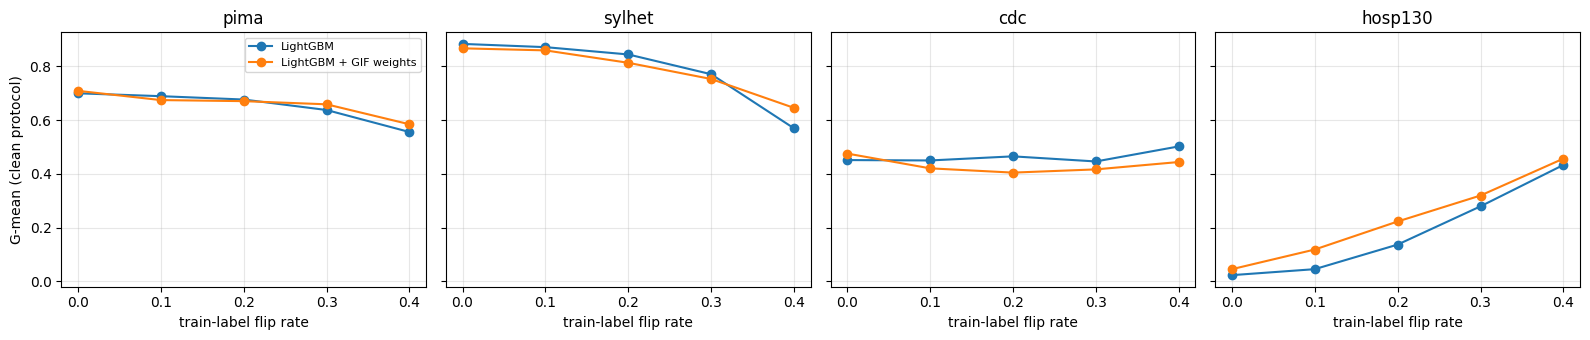

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, name in zip(axes, DATASETS):
    for model, g in df[(df.dataset == name) & (df.protocol == "clean")].groupby("model"):
        m = g.groupby("noise_rate")["gmean"].mean()
        ax.plot(m.index, m.values, marker="o", label=model)
    ax.set_title(name); ax.set_xlabel("train-label flip rate"); ax.grid(alpha=.3)
axes[0].set_ylabel("G-mean (clean protocol)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(find_results_dir() / "04_zhang_gmean_vs_noise.png", dpi=150); plt.show()